# 感知器 Perceptron（1958）

- **核心原理**：線性分界、錯誤驅動更新
- **變體**：多層感知器 MLP（第二章）；Pocket、Averaged／Voted Perceptron
- **推薦資料集**：Iris（只取兩類）。主資料是 setosa vs versicolor（線性可分）；第 5 節調參另外用 versicolor vs virginica（線性不可分）

本章依照 README 的「每章標準流程」：EDA → Baseline → 手寫模型 → 套件實作 → 調參 → 測試集評估 → 診斷 → 本章小結。

> 本章原本在流程確定前完成。依新版流程**補寫**的部分：每一節的段落結構、型別提示與 ✅ 檢查點、TODO 1–2、TODO 5–10、第 5–7 節，答案由 Claude 撰寫，標題註明「補寫」；
> TODO 3 的程式與 TODO 4 的答案是原本的作答（TODO 4 由原本的「觀察」整理成問答格式）。


---
## 1. 資料與探索性資料分析（EDA）

觀察直接寫在每格程式最上面的註解（`# 觀察：`）。標籤：0 = setosa、1 = versicolor。


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from ml_dl_llm.data import load_iris_binary

X_train, X_test, y_train, y_test = load_iris_binary()
train = X_train.assign(label=y_train)

print("train / test：", X_train.shape, X_test.shape)


train / test： (80, 4) (20, 4)


In [3]:
# 觀察：80 筆資料、4 個特徵全部都是連續型資料（float64），沒有缺值。
X_train.info()

<class 'pandas.DataFrame'>
Index: 80 entries, 15 to 25
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  80 non-null     float64
 1   sepal width (cm)   80 non-null     float64
 2   petal length (cm)  80 non-null     float64
 3   petal width (cm)   80 non-null     float64
dtypes: float64(4)
memory usage: 3.1 KB


In [4]:
# 觀察：平衡樣本，兩類各 40 筆 → 「永遠猜同一類」的 accuracy 是 0.5。
y_train.value_counts()


target
0    40
1    40
Name: count, dtype: int64

In [5]:
# 觀察：特徵範圍
#   petal length 雖然平均較小，但是變異很大；sepal length 平均較大，但是變異很小；兩者的 width 都沒什麼特別的。
#   四個特徵都是公分、尺度相近（不像第二章差到 10³ 倍），但平均都離 0 很遠（sepal length 約 5.5）（TODO 1 (3)）。
X_train.describe().T


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),80.0,5.4575,0.620693,4.3,5.0,5.45,5.825,7.0
sepal width (cm),80.0,3.0825,0.487509,2.0,2.8,3.00,3.400,4.4
petal length (cm),80.0,2.8650,1.435014,1.1,1.5,2.45,4.225,5.1
petal width (cm),80.0,0.7875,0.557657,0.1,0.2,0.80,1.300,1.8


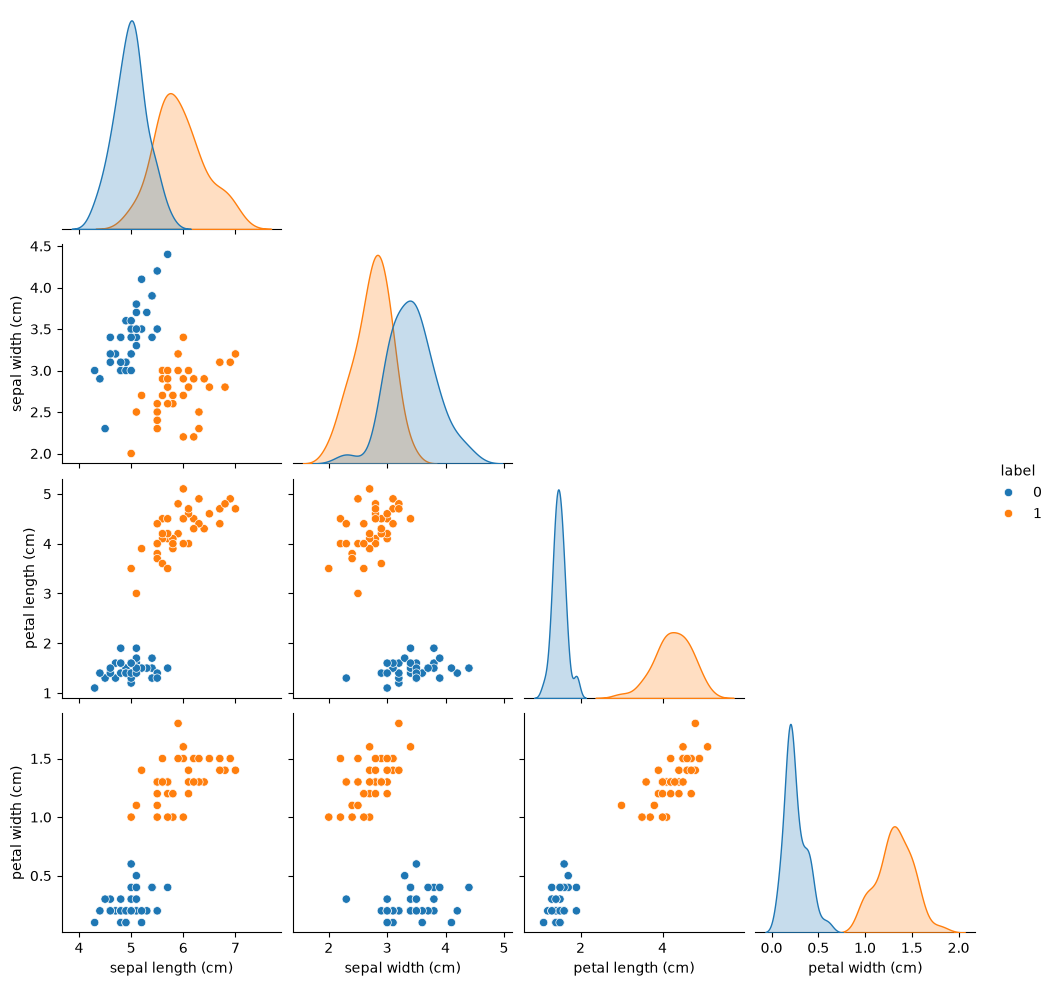

In [6]:
# 觀察：線性可分性 —— 完全線性可分：petal length、petal width 的散點圖上，兩類之間有一大段空白。
sns.pairplot(train, hue="label", corner=True)
plt.show()


In [7]:
# 觀察：基本上 petal length、petal width 就可以做切分了，兩類的範圍完全不重疊、是很明顯的兩個區段（TODO 1 (1)）。
display(train.groupby("label").agg(["min", "max"]).T)

gap = {
    c: float(
        train.loc[train.label == 1, c].min() - train.loc[train.label == 0, c].max()
    )
    for c in X_train.columns
}
print(
    "「versicolor 最小值 − setosa 最大值」（> 0 代表單一特徵就能完全分開）：",
    {k: round(v, 2) for k, v in gap.items()},
)

label                    0    1
sepal length (cm) min  4.3  5.0
                  max  5.7  7.0
sepal width (cm)  min  2.3  2.0
                  max  4.4  3.4
petal length (cm) min  1.1  3.0
                  max  1.9  5.1
petal width (cm)  min  0.1  1.0
                  max  0.6  1.8

「versicolor 最小值 − setosa 最大值」（> 0 代表單一特徵就能完全分開）： {'sepal length (cm)': -0.7, 'sepal width (cm)': -2.4, 'petal length (cm)': 1.1, 'petal width (cm)': 0.4}


### TODO 1（問答）EDA 小結

> **(1)** 線性可分：
>
> **(a)** 讀上一格的表：哪些特徵「單獨一個」就能把兩類完全分開？兩類之間的空隙多大？
>
> **(b)** 定義：資料線性可分 ⇔ 存在一個超平面 $w \cdot x + b = 0$ 讓兩類分在兩側。「單一特徵就分得開」為什麼一定代表線性可分？
>
> **(c)** 先寫下你的預測：感知器在這份資料上會不會收斂？大約需要幾次更新？（3 會驗證）

**(a)** petal length（setosa 最大 1.9、versicolor 最小 3.0，空隙 1.1 cm）與 petal width（0.6 vs 1.0，空隙 0.4 cm）。兩個 sepal 特徵的範圍重疊（差值為負），單獨用不行。

**(b)** 「petal length ≤ 2.45 → setosa」本身就是一個超平面：取 $w = (0, 0, 1, 0)$、$b = -2.45$，$w \cdot x + b = 0$ 就是 petal length = 2.45 這個平面。單一特徵的門檻是「只有一個係數不為 0」的特例，所以一定線性可分；反過來不成立（兩類可能要斜線才分得開）。

**(c)** 會收斂：Novikoff 定理保證線性可分時，更新次數有上限 $(R/\gamma)^2$。空隙相對於資料範圍很大（$\gamma$ 大）→ 預期只需要極少次更新。實測（3）：標準化後 seed 42 只更新 **1 次**。

> **(2)** 測試集只有 20 筆：
>
> **(a)** accuracy 的最小刻度是多少？
>
> **(b)** 如果好幾個模型在這份資料上都是 1.0，測試集還能分辨它們誰比較好嗎？
>
> **(c)** 那要怎麼練習「調參」與「比較模型」？

**(a)** 1/20 = 0.05：錯 1 筆就是 0.95。

**(b)** 不能。資料這麼好分，任何合理的線性分類器都會是 1.0（第 2 節的 stump 就是）；分數到頂了（ceiling effect），測試集只能說「都沒錯」，說不出誰的分界線比較好。

**(c)** 兩件事：① 用交叉驗證取代單一測試集；② 換一個「有難度」的問題 —— 第 5 節改用線性不可分的 versicolor vs virginica。

> **(3)** 尺度：四個特徵都是公分、標準差 0.5–1.4，尺度相近（不像第二章差 10³ 倍）；但平均都離 0 很遠（sepal length 約 5.5）。感知器的 $w$、$b$ 都從 0 開始，分界線一開始通過原點，而 $b$ 每次更新只動 $\pm\eta$。預測：不標準化時會怎樣？

需要更多次更新：資料中心在 $(5.5, 3.1, 2.9, 0.8)$ 附近，離原點約 7；分界線要從原點「搬」到兩類之間，主要靠 $b$ 一次 $\pm 1$ 慢慢平移，而 $w$ 每次加上整個 $x$（長度約 7），方向會被「離原點很遠」這件事主導。標準化把資料中心移到原點，分界線一開始就在資料中間，只需要轉方向。（TODO 4 驗證：raw 平均 8.41 次、標準化 1.76 次。）


---
## 2. Baseline

- **Dummy**：不看特徵，永遠猜多數類（兩類各半，所以就是猜第一類）。
- **Decision stump**：只切一刀的決策樹（`max_depth=1`）—— 只用「一個特徵＋一個門檻」，是最簡單的「有看特徵」的模型。

指標用 accuracy（兩類平衡）。5-fold 分層 CV，整章共用同一組切分。


In [8]:
from sklearn.base import BaseEstimator
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier

# 使用 Stratified 保持 label (y) 的分布在5份資料內都一樣
# 不考慮 X 特徵的分布
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def cv_summary(
    model: BaseEstimator, X: pd.DataFrame = X_train, y: pd.Series = y_train, cv=cv
) -> dict[str, str]:
    """CV。回傳 {"train_acc": "平均 ± 標準差", "val_acc": "平均 ± 標準差"}。"""
    s = cross_validate(model, X, y, cv=cv, scoring="accuracy", return_train_score=True)
    return {
        "train_acc": f"{s['train_score'].mean():.4f} ± {s['train_score'].std():.4f}",
        "val_acc": f"{s['test_score'].mean():.4f} ± {s['test_score'].std():.4f}",
    }


stump = DecisionTreeClassifier(max_depth=1, random_state=42)
baseline = pd.DataFrame(
    {
        "Dummy most_frequent": cv_summary(DummyClassifier(strategy="most_frequent")),
        "Decision stump": cv_summary(stump),
    }
).T
display(baseline)
stump.fit(X_train, y_train)
print(
    "stump 用的特徵與門檻：",
    X_train.columns[stump.tree_.feature[0]],
    "≤",
    round(stump.tree_.threshold[0], 2),
)

,train_acc,val_acc
Dummy most_frequent,0.5000 ± 0.0000,0.5000 ± 0.0000
Decision stump,1.0000 ± 0.0000,1.0000 ± 0.0000


stump 用的特徵與門檻： petal length (cm) ≤ 2.45


### TODO 2（問答）

> **(1)** Dummy 的 accuracy 為什麼剛好是 0.5、標準差是 0？

兩類各 40 筆，most_frequent 在平手時取編號較小的類別（0 = setosa），每一筆都猜 0。`StratifiedKFold` 讓每個驗證 fold 都是 8 : 8 → 每個 fold 都剛好 0.5，標準差 0。

> **(2)** Decision stump 只切一刀（petal length ≤ 2.45）就是 1.0。
>
> **(a)** 這代表 baseline 已經到哪裡了？後面的模型還有進步空間嗎？
>
> **(b)** stump 的門檻 2.45 剛好是哪兩個數的中點？（對照 TODO 1 (1) 的表）這個位置有什麼好處？
>
> **(c)** 感知器停下來的分界線，會不會也剛好在中點？

**(a)** baseline 已經是滿分，沒有進步空間 —— 這份資料能拿來「驗證感知器寫得對不對」（會收斂、會分對），但不能拿來「比較模型好壞」（TODO 1 (2)）。

**(b)** setosa 最大 1.9 與 versicolor 最小 3.0 的中點 $(1.9 + 3.0)/2 = 2.45$。決策樹把門檻放在相鄰兩個值的中間，離兩邊最近的樣本都一樣遠（各 0.55）→ 在這一個軸上是「margin 最大」的切法，新樣本稍微超出訓練範圍也不容易分錯。

**(c)** 不會。感知器只要分對就停，不在乎離兩類多遠：分界線停在哪裡取決於資料順序（seed），可能貼著某一類（TODO 5 (2) 量化：margin 從 0.011 到 0.84 都有）。「分對」與「分得好」是兩回事，最大 margin 是 SVM（第 7 章）的目標。


---
## 3. 手寫模型

標籤改用 $y \in \{-1, +1\}$（感知器原始論文的寫法，`signed=True`）。

| 項目 | 公式 |
| --- | --- |
| 預測 | $\hat y = \operatorname{sign}(w \cdot x + b)$，分界是超平面 $w \cdot x + b = 0$ |
| 更新條件 | 分錯或剛好落在線上：$y_i (w \cdot x_i + b) \le 0$ |
| 更新 | $w \leftarrow w + \eta\, y_i x_i$、$b \leftarrow b + \eta\, y_i$；分對就不動 |
| 停止 | 一整個 epoch 都沒有分錯（`errors == 0`），或跑滿 `max_epochs` |


In [9]:
from typing import Self
from numpy.typing import ArrayLike
from sklearn.preprocessing import StandardScaler

# 取出帶有 -1／+1 標籤的資料
X_train, X_test, y_train, y_test = load_iris_binary(signed=True)

# 訓練集標準化（scaler 只用訓練集 fit，標準化用到驗證集或測試集就相當于資訊洩漏，提前偷看答案了，模型性能評估會趨於樂觀）
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)


class Perceptron:
    """感知器（Rosenblatt, 1958）。y 必須是 −1／+1。

    shuffle=True：每個 epoch 用 seed 打亂資料順序；False：照原始順序（用來跟 sklearn 逐步比對）。
    """

    def __init__(
        self,
        lr: float = 1.0,
        max_epochs: int = 100,
        seed: int = 42,
        shuffle: bool = True,
    ) -> None:
        self.lr = lr
        self.max_epochs = max_epochs
        self.seed = seed
        self.shuffle = shuffle

    def fit(self, X: ArrayLike, y: ArrayLike) -> Self:
        """X (n, d)、y (n,) ∈ {−1, +1}。學到 w_ (d,)、b_，errors_ 是每個 epoch 的更新次數；回傳 self。"""
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        n_row, n_column = X.shape
        self.w_ = np.zeros(n_column)
        self.b_ = 0.0
        self.errors_ = []
        # 用途1：每一個epoch的順序都不一樣，同一個rng每呼叫一次permutation，內部狀態就往前走，所以第1, 2, 3, ...個epoch可以拿到不同的排列
        # 用途2：種子固定，每次實驗結果可以重現
        # 迴圈之前宣告是為了讓epoch之間的permutation可以打亂
        rng = np.random.default_rng(self.seed)

        for epoch in range(self.max_epochs):
            # 初始化 errors
            errors = 0
            # 打亂看資料的順序，避免資料的排列順序影響參數更新與收斂速度
            order = rng.permutation(n_row) if self.shuffle else range(n_row)
            for i in order:
                x = X[i, :]  # 挑出第 i 筆資料
                # 特徵與權重做內積再加 intercept 當作分數：> 0 分為正類（+1），反之為負類（−1）
                score = np.dot(self.w_, x) + self.b_
                # TODO 3（程式）：錯誤驅動更新
                #   - 條件：分錯或剛好落在線上 y·score ≤ 0
                #   - 注意要加上等於 0：一開始權重跟 intercept 都是 0，不加上 0 永遠學不到東西
                #   - 更新：
                #         w <- w + lr·y·x
                #         b <- b + lr·y
                #   - 有沒有分對不用管 score 的值，只看 y·score 的符號：> 0 分對，≤ 0 分錯
                #     score 的大小代表離分界線多遠（和 margin 有關），只是感知器判斷對錯時用不到
                #   - 核心原理是看 sign，但不能拿 sign 來更新參數：sign 的輸出只有 ±1，導數都是 0，梯度沒有資訊
                #     → 改用 y·(wᵀx + b) 建構損失函數 L = max(0, −y·(wᵀx + b))
                #     分對的點 L = 0，不會產生更新；只有分錯的點才有損失
                #   - 分錯時 L = −y·(wᵀx + b)，對 w、b 微分：∂L/∂w = −y·x、∂L/∂b = −y
                #     梯度下降是「減掉梯度」→ w ← w − lr·(−y·x) = w + lr·y·x，b 同理，就是上面的更新式
                if score * y[i] <= 0:
                    errors += 1
                    self.w_ += self.lr * y[i] * x
                    self.b_ += self.lr * y[i]
            self.errors_.append(errors)
            if errors == 0: # 沒分錯就停止了
                break
        return self

    def decision_function(self, X: ArrayLike) -> np.ndarray:
        """X (n, d) → (n,) 的分數 w·x + b（未正規化、不是機率）。"""
        return np.asarray(X, dtype=float) @ self.w_ + self.b_

    def predict(self, X: ArrayLike) -> np.ndarray:
        """X (n, d) → (n,) 的 −1／+1 預測。"""
        score = self.decision_function(X)
        return np.where(score >= 0, 1, -1)  # 只要分正副類就好


# 跑模型
model = Perceptron().fit(X_train_s, y_train)
print("每個 epoch 更新次數：", model.errors_)
print("總更新次數：", sum(model.errors_))
print("epoch 數：", len(model.errors_))
print("權重 w：", model.w_, "  b：", model.b_)
print("✅ 最後一個 epoch 的更新次數：", model.errors_[-1], "（線性可分 → 應 = 0）")
print(
    "✅ 訓練集 accuracy：", (model.predict(X_train_s) == y_train).mean(), "（應 = 1.0）"
)

每個 epoch 更新次數： [1, 0]
總更新次數： 1
epoch 數： 2
權重 w： [ 2.1765521  -0.5831331   1.35692615  1.10527565]   b： 1.0
✅ 最後一個 epoch 的更新次數： 0 （線性可分 → 應 = 0）
✅ 訓練集 accuracy： 1.0 （應 = 1.0）


In [10]:
# 比較訓練集標準化或不標準化的表現

print("===== 不執行標準化 =====")
model_raw = Perceptron().fit(X_train, y_train)
print("每個 epoch 更新次數：", model_raw.errors_)
print("總更新次數：", sum(model_raw.errors_))
print("epoch 數：", len(model_raw.errors_))
print("權重 w：", model_raw.w_)
print("訓練集預測：", (model_raw.predict(X_train) == y_train).mean())
print("\n")

print("===== 執行標準化 =====")
model_s = Perceptron().fit(X_train_s, y_train)
print("每個 epoch 更新次數：", model_s.errors_)
print("總更新次數：", sum(model_s.errors_))
print("epoch 數：", len(model_s.errors_))
print("權重 w：", model_s.w_)
print("訓練集預測：", (model_s.predict(X_train_s) == y_train).mean())
print("\n")

===== 不執行標準化 =====
每個 epoch 更新次數： [5, 0]
總更新次數： 5
epoch 數： 2
權重 w： [-1.2 -4.2  5.1  2.3]
訓練集預測： 1.0


===== 執行標準化 =====
每個 epoch 更新次數： [1, 0]
總更新次數： 1
epoch 數： 2
權重 w： [ 2.1765521  -0.5831331   1.35692615  1.10527565]
訓練集預測： 1.0




       updates         epochs         train_acc          
          mean min max   mean min max      mean  min  max
data                                                     
raw       8.41   2  14   2.04   2   3       1.0  1.0  1.0
scaled    1.76   1   4   2.10   2   4       1.0  1.0  1.0


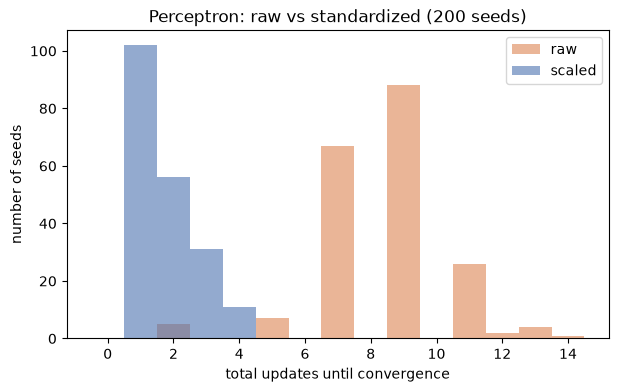

In [11]:
# 比較不同 seeds 下收斂的情況（TODO 4）
import pandas as pd

seeds = range(200)
rows = []
for seed in seeds:
    for name, X in [("raw", X_train), ("scaled", X_train_s)]:
        m = Perceptron(seed=seed).fit(X, y_train)
        rows.append(
            {
                "seed": seed,
                "data": name,
                "epochs": len(m.errors_),
                "updates": sum(m.errors_),
                "train_acc": (m.predict(X) == y_train).mean(),
            }
        )

runs = pd.DataFrame(rows)

# 摘要統計：兩個版本的更新次數、epoch 數、訓練準確率
summary = runs.groupby("data")[["updates", "epochs", "train_acc"]].agg(
    ["mean", "min", "max"]
)
print(summary.round(2))

# 分布圖：總更新次數
fig, ax = plt.subplots(figsize=(7, 4))
for name, color in [("raw", "#DD8452"), ("scaled", "#4C72B0")]:
    data = runs.loc[runs["data"] == name, "updates"]
    ax.hist(
        data,
        bins=range(0, data.max() + 2),
        alpha=0.6,
        label=name,
        color=color,
        align="left",
    )
ax.set_xlabel("total updates until convergence")
ax.set_ylabel("number of seeds")
ax.set_title("Perceptron: raw vs standardized (200 seeds)")
ax.legend()
plt.show()

### TODO 4（問答）

> **(1)** 200 個 seed 下，raw 與標準化各需要幾次更新、幾個 epoch 才收斂？兩者最後都能分對嗎？

由圖可知，不執行標準化時，雖然最後都會分正確（因為資料確實完全線性可分），但需要更多次更新才能收斂（200 個 seed 平均約 8.41 次，標準化後約 1.76 次）。

**補充**：epoch 數幾乎一樣（raw 2.04、標準化 2.10）—— 差別在「每個 epoch 裡分錯幾次」，不是 epoch 數。最後一個 epoch 只是確認「全部分對了」（errors = 0）才停下來，所以 epoch 數最少就是 2。

> **(2)** 為什麼標準化會讓收斂變快？（提示：Novikoff 收斂定理：更新次數 ≤ $(R/\gamma)^2$）

原因是標準化讓資料以原點為中心、縮小了 $R$，而收斂上限是 $(R/\gamma)^2$；未標準化時資料離原點很遠，分界線主要靠每次只移動 ±1 的 bias 慢慢「搬」過去。


### 補充說明：Novikoff 收斂定理（1962）

> 給做應用、沒學過或忘記這個定理的人。一句話：**資料線性可分時，感知器一定會停，而且分錯的次數有上限 $(R/\gamma)^2$。**

#### 1. 定理在說什麼

兩個前提：

- **$R$（資料有多大）**：所有樣本到原點的距離都不超過 $R$，即 $\|x_i\| \le R$。
- **$\gamma$（兩類之間的空隙有多寬）**：存在一條把兩類完全分開的線（單位法向量 $u$，$\|u\| = 1$），而且每個樣本離這條線至少 $\gamma$：$y_i\,(u \cdot x_i) \ge \gamma > 0$。$\gamma > 0$ 就是「線性可分」。

結論：不管資料順序、樣本數 $n$、維度 $d$ 是多少，感知器**分錯（更新）的總次數**

$$k \;\le\; \left(\frac{R}{\gamma}\right)^2$$

**bias 怎麼處理**：把 $x$ 補一個常數 1、把 $b$ 併進 $w$，即 $\tilde x = (x, 1)$、$\tilde w = (w, b)$，更新式 $\tilde w \leftarrow \tilde w + y\,\tilde x$ 就同時包含了 $w \leftarrow w + y x$ 和 $b \leftarrow b + y$。定理裡的 $R$、$\gamma$ 都在這個補了 1 的空間裡算。

#### 2. 直覺（不用記證明也能用）

$R/\gamma$ 可以理解成「**資料的尺寸 ÷ 空隙的寬度**」，是這個問題有多「擠」：

- 空隙寬、資料集中（$R/\gamma$ 小）→ 隨便更新幾次就分開了。
- 空隙窄、資料很分散或離原點很遠（$R/\gamma$ 大）→ 分界線要一點一點調，更新次數多。

重要的是**比值**，不是 $R$ 或 $\gamma$ 單獨的大小。

#### 3. 證明的骨架（兩個不等式）

設正確答案的方向是 $u$，從 $w = 0$ 開始，已經更新了 $k$ 次：

1. **方向越來越對（線性成長）**：每次更新加上 $y x$，而 $y\,(u \cdot x) \ge \gamma$ → $w \cdot u$ 每次至少增加 $\gamma$ → $w \cdot u \ge k\gamma$。
2. **長度長得慢（只有 $\sqrt{k}$）**：
   - $y\,(w \cdot x)$ 就是程式裡的 `y * score`（bias 已併進 $w$，$w \cdot x$ 就是 score）。感知器只在分錯時更新，所以每一次更新的當下一定是 $y\,(w \cdot x) \le 0$；分對的點不更新，$w$ 的長度也不變，不用算。
   - 代回展開式：

     $$\|w + yx\|^2 = \|w\|^2 + \underbrace{2y\,(w \cdot x)}_{\le 0\text{（因為分錯）}} + \underbrace{y^2\|x\|^2}_{= \|x\|^2 \le R^2\text{（因為 } y^2 = 1\text{）}}$$

   - 中間那項不是 0 就是負的，只會讓長度變小或不變 → $\|w_{\text{新}}\|^2 \le \|w_{\text{舊}}\|^2 + R^2$：每更新一次，長度平方最多增加 $R^2$。
   - 從 $w = 0$ 開始，更新 $k$ 次後 $\|w\|^2 \le kR^2$，也就是 $\|w\| \le \sqrt{k}\,R$。

兩者合起來：$k\gamma \le w \cdot u \le \|w\| \le \sqrt{k}\,R$，所以 $k \le (R/\gamma)^2$。

意思是：$w$ 和正確方向的夾角餘弦 $\dfrac{w \cdot u}{\|w\|} \ge \sqrt{k}\,\dfrac{\gamma}{R}$ 會隨更新次數一直變大，但餘弦不能超過 1，所以更新次數不可能無限多。

#### 4. 對應到這份 notebook

| 現象 | 定理怎麼解釋 |
| --- | --- |
| setosa vs versicolor 一定收斂（200 個 seed 都分對） | 線性可分，$\gamma > 0$，有上限 |
| 不標準化平均 8.41 次、標準化 1.76 次（TODO 4） | raw 資料中心離原點約 7，$R$ 很大但兩類空隙沒有變寬 → $R/\gamma$ 大；標準化把資料移到原點附近，比值變小 |
| 學習率不影響結果（TODO 6） | 從 0 開始時 $\eta$ 只是把 $w$ 等比例放大，不改變分錯的次數，所以定理裡根本沒有 $\eta$ |
| versicolor vs virginica 永遠停不下來（TODO 7） | 線性不可分，不存在 $\gamma > 0$，前提不成立，沒有任何保證 |

#### 5. 做應用時要記得的限制

- **只是上限**：實際更新次數通常遠小於 $(R/\gamma)^2$，不能拿來精確預測要跑多久。
- **只保證「訓練集分對」**：不保證分界線好（margin 可能很小，TODO 5 (2)），也不保證測試集表現。
- **前提很嚴格**：真實資料幾乎都有雜訊、不完全可分，這時要改用 Pocket、Averaged perceptron，或直接用邏輯回歸、SVM。
- **與 $n$、$d$ 無關**：高維度本身不會讓感知器變慢，關鍵是空隙相對資料尺寸有多寬。這個「看 margin 不看維度」的想法後來延伸成 SVM（第 7 章）。

---
## 4. 套件實作：sklearn `Perceptron`

sklearn 的 `Perceptron` 等價於 `SGDClassifier(loss="perceptron", learning_rate="constant", eta0=1, penalty=None)`。
標準化包進 `Pipeline`，直接傳原始資料。


In [12]:
from sklearn.linear_model import Perceptron as SkPerceptron
from sklearn.pipeline import make_pipeline

# 標準化 + 感知機綁成一個 pipeline：fit 和 predict 都會自動先標準化
sk_model = make_pipeline(StandardScaler(), SkPerceptron(random_state=42))
sk_model.fit(X_train, y_train)  # 注意：直接傳原始資料

clf = sk_model[-1]  # 取出 pipeline 最後一步（感知機本體）
print("epoch 數 n_iter_：", clf.n_iter_)
print("權重 w：", clf.coef_[0], "  截距 b：", clf.intercept_[0])
print("手寫 w：", model.w_, "  b：", model.b_)
print(
    "✅ 手寫 vs sklearn 測試集 predict 一致比例：",
    (model.predict(X_test_s) == sk_model.predict(X_test)).mean(),
    "（應 = 1.0）",
)

epoch 數 n_iter_： 6
權重 w： [ 0.87953781 -0.3767143   1.14655     1.28572882]   截距 b： 1.0
手寫 w： [ 2.1765521  -0.5831331   1.35692615  1.10527565]   b： 1.0
✅ 手寫 vs sklearn 測試集 predict 一致比例： 1.0 （應 = 1.0）


In [13]:
# 逐步比對：兩邊都不打亂、照同樣的順序、跑同樣的 epoch 數 → 更新序列應該一模一樣
for E in [1, 3, 10]:
    mine = Perceptron(shuffle=False, max_epochs=E).fit(X_train_s, y_train)
    sk_ns = SkPerceptron(shuffle=False, max_iter=E, tol=None).fit(X_train_s, y_train)
    print(
        f"max_epochs = {E:2d}：✅ w 最大差異 {np.abs(mine.w_ - sk_ns.coef_[0]).max():.1e}、"
        f"b 差異 {abs(mine.b_ - sk_ns.intercept_[0]):.1e}（應 = 0）"
    )


def geometric_margin(w: np.ndarray, b: float, X: np.ndarray, y: np.ndarray) -> float:
    """幾何 margin：min_i y_i (w·x_i + b) / ‖w‖。> 0 代表全部分對，數值越大代表離分界越遠。"""
    return float((y * (X @ w + b)).min() / np.linalg.norm(w))


ytr = y_train.to_numpy()
print("\n幾何 margin（訓練集，標準化後的空間）：")
print(
    "  手寫（seed 42，shuffle）：",
    round(geometric_margin(model.w_, model.b_, X_train_s, ytr), 4),
)
print(
    "  sklearn（random_state 42）：",
    round(geometric_margin(clf.coef_[0], clf.intercept_[0], X_train_s, ytr), 4),
)
margins = [
    geometric_margin(m.w_, m.b_, X_train_s, ytr)
    for m in (Perceptron(seed=s).fit(X_train_s, y_train) for s in range(200))
]
print(
    f"  200 個 seed：min {min(margins):.4f}、中位數 {np.median(margins):.4f}、max {max(margins):.4f}"
)

max_epochs =  1：✅ w 最大差異 0.0e+00、b 差異 0.0e+00（應 = 0）
max_epochs =  3：✅ w 最大差異 0.0e+00、b 差異 0.0e+00（應 = 0）
max_epochs = 10：✅ w 最大差異 0.0e+00、b 差異 0.0e+00（應 = 0）

幾何 margin（訓練集，標準化後的空間）：
  手寫（seed 42，shuffle）： 0.4176
  sklearn（random_state 42）： 0.6509
  200 個 seed：min 0.0113、中位數 0.4468、max 0.8370


### TODO 5（問答）

> **(1)** 兩邊都不打亂（`shuffle=False`）時，手寫版與 sklearn 的 $w$、$b$ 完全一樣（差異 0）；用預設設定時卻不一樣（sklearn 跑了 6 個 epoch、$w$ 也不同）。
>
> **(a)** 讀輸出：預設設定下兩者的 $w$ 各是多少？測試集的預測一樣嗎？
>
> **(b)** 列出兩邊的差異：資料順序、停止條件、標籤。哪一個造成 $w$ 不同？哪一個只影響 `n_iter_`？

**(a)** 手寫 $w = (2.18, -0.58, 1.36, 1.11)$、sklearn $w = (0.88, -0.38, 1.15, 1.29)$，$b$ 都是 1；測試集預測完全一致（20 筆全對）。

**(b)** 先看實際發生了什麼，再看差異表。

**兩邊其實都只更新了 1 次，而且都發生在第 1 個 epoch 看到的第 1 筆：**

- 一開始 $w = 0$、$b = 0$，第一筆樣本的 score 一定是 0 → $y \cdot 0 = 0 \le 0$ → 不管它是哪一類，**第一筆一定會被更新**。
- 更新後 $w = y \cdot x_{\text{第一筆}}$、$b = y$。兩邊的 $b$ 都是 1，代表兩邊看到的第一筆剛好都是 +1（versicolor），所以 $w$ 就**直接等於那一筆的 $x$**。
- 更新這一次之後，訓練集已經全部分對，之後就不再更新。

| | 第一筆看到的樣本 | 最後的 $w$（= 那一筆標準化後的 $x$） | $b$ |
| --- | --- | --- | --- |
| 手寫（`np.random.default_rng(42)`） | `X_train_s` 第 33 列（從 0 起算） | $(2.18, -0.58, 1.36, 1.11)$ | 1 |
| sklearn（`random_state=42`） | `X_train_s` 第 13 列 | $(0.88, -0.38, 1.15, 1.29)$ | 1 |

可以自己驗證：`X_train_s[33]` 等於 `model.w_`，`X_train_s[13]` 等於 `clf.coef_[0]`。

→ **係數不同的原因只有一個：兩邊打亂資料的方式不同，第一筆看到的樣本不同。** 同樣寫 42 也沒用：42 只是種子，NumPy 的 `default_rng`（PCG64）和 sklearn 內部的打亂程式是兩套不同的亂數演算法，同一個種子產生的排列不一樣。

| 差異 | 手寫 | sklearn | 影響 |
| --- | --- | --- | --- |
| 資料順序 | `np.random.default_rng(42).permutation` | sklearn 自己的亂數（`random_state=42`，另一套產生器） | **造成 $w$ 不同**：第一筆看到的樣本不同，$w$ 就等於不同的 $x$ |
| 停止條件 | 一個 epoch 都沒錯就停 | `tol=1e-3`、`n_iter_no_change=5`：loss 連續 5 個 epoch 沒改善才停 | 只影響 `n_iter_`（2 vs 6）：sklearn 第 1 個 epoch 結束時的 $w$ 就已經是最終答案，第 2–6 個 epoch 一次都沒更新 |
| 標籤 | −1／+1 | 內部把兩類轉成 −1／+1 | 沒影響（這裡傳進去的本來就是 −1／+1） |

- 更新規則本身一模一樣（`shuffle=False` 時差異是 0 而不是 1e-15）：sklearn 的 perceptron loss 在 $y \cdot (w \cdot x + b) \le 0$ 時更新，跟手寫版的條件（含等號）相同。
- → 驗證手寫模型時，要先把「隨機性」與「停止條件」對齊，再比較係數。

> **(2)** 兩組 $w$ 都把訓練集全部分對、測試集預測也一樣。哪一組「比較好」？
>
> **(a)** 定義：幾何 margin $= \min_i y_i (w \cdot x_i + b) / \|w\|$，是「離分界線最近的訓練樣本」到分界線的距離。讀輸出：手寫與 sklearn 各是多少？200 個 seed 的範圍？
>
> **(b)** 如果有一個新樣本落在兩類之間的空白區，margin 大的分界線還是 margin 小的比較可能分對？

**(a)** 手寫 0.418、sklearn 0.651；200 個 seed：0.011–0.837（中位數 0.447）。同樣「全部分對」，分界線離最近樣本的距離可以差 70 倍。

**(b)** margin 大的。margin 0.011 的分界線幾乎貼著某個訓練樣本，新樣本只要比那個樣本稍微再靠近一點就會被分錯；margin 大的分界線兩側都留有緩衝。

- **感知器的解不唯一**：它只保證「找到一條能分開的線」，找到哪一條由資料順序決定，不追求「最好」。
- 「margin 最大的分界線」是唯一的 → SVM（第 7 章）；感知器的 margin 只是運氣。


---
## 5. 調參

全程只用 `X_train`。感知器的超參數（sklearn `Perceptron`／`SGDClassifier(loss="perceptron")`）：

| 類別 | 超參數 | 說明 |
| --- | --- | --- |
| 容量 | — | 模型永遠是一個超平面，容量固定（要更大的容量 → 特徵轉換、kernel、MLP） |
| 正則化 | `penalty`（None、`"l2"`）、`alpha` | 每一步把 w 往 0 拉一點 |
| 最佳化 | `eta0`（學習率）、`max_iter`、`shuffle`／`random_state` | 下面先驗證：不加正則化時，學習率完全不影響結果 |
| 最佳化 | `average` | 回傳「所有歷史 w 的平均」而不是最後一個 w（averaged perceptron） |

### 5A. 主資料（setosa vs versicolor）


In [14]:
# 學習率真的重要嗎？w、b 從 0 開始時，換 lr 只是把整條更新序列等比例縮放
runs = {
    lr: Perceptron(lr=lr, seed=42).fit(X_train_s, y_train) for lr in [0.01, 1.0, 100.0]
}
for lr, m in runs.items():
    print(
        f"lr = {lr:>6}：errors_ = {m.errors_}，w / lr = {np.round(m.w_ / lr, 4)}，b / lr = {m.b_ / lr:.4f}"
    )
ref = runs[1.0]
print(
    "✅ 三個 lr 的 errors_ 完全相同：",
    all(m.errors_ == ref.errors_ for m in runs.values()),
)
print(
    "✅ w / lr 的最大差異：",
    max(np.abs(m.w_ / lr - ref.w_).max() for lr, m in runs.items()),
    "（應 < 1e-12）",
)

# 主資料上，幾種設定的 CV
from sklearn.linear_model import SGDClassifier

main_tbl = pd.DataFrame(
    {
        "Perceptron (default)": cv_summary(
            make_pipeline(StandardScaler(), SkPerceptron(random_state=42))
        ),
        "Perceptron raw (no scaler)": cv_summary(SkPerceptron(random_state=42)),
        "Perceptron eta0=0.01": cv_summary(
            make_pipeline(StandardScaler(), SkPerceptron(eta0=0.01, random_state=42))
        ),
        "Perceptron l2 alpha=0.01": cv_summary(
            make_pipeline(
                StandardScaler(),
                SkPerceptron(penalty="l2", alpha=0.01, random_state=42),
            )
        ),
        "Averaged perceptron": cv_summary(
            make_pipeline(
                StandardScaler(),
                SGDClassifier(
                    loss="perceptron",
                    learning_rate="constant",
                    eta0=1.0,
                    penalty=None,
                    average=True,
                    random_state=42,
                ),
            )
        ),
    }
).T
display(pd.concat([baseline, main_tbl]))

lr =   0.01：errors_ = [1, 0]，w / lr = [ 2.1766 -0.5831  1.3569  1.1053]，b / lr = 1.0000
lr =    1.0：errors_ = [1, 0]，w / lr = [ 2.1766 -0.5831  1.3569  1.1053]，b / lr = 1.0000
lr =  100.0：errors_ = [1, 0]，w / lr = [ 2.1766 -0.5831  1.3569  1.1053]，b / lr = 1.0000
✅ 三個 lr 的 errors_ 完全相同： True
✅ w / lr 的最大差異： 0.0 （應 < 1e-12）


,train_acc,val_acc
Dummy most_frequent,0.5000 ± 0.0000,0.5000 ± 0.0000
Decision stump,1.0000 ± 0.0000,1.0000 ± 0.0000
Perceptron (default),1.0000 ± 0.0000,1.0000 ± 0.0000
Perceptron raw (no scaler),1.0000 ± 0.0000,1.0000 ± 0.0000
Perceptron eta0=0.01,1.0000 ± 0.0000,1.0000 ± 0.0000
Perceptron l2 alpha=0.01,1.0000 ± 0.0000,1.0000 ± 0.0000
Averaged perceptron,1.0000 ± 0.0000,1.0000 ± 0.0000


### TODO 6（問答）

> **(1)** 主資料上，表格裡每一種設定（不標準化、改學習率、加 L2、平均）的 CV 都是 1.0 ± 0。這代表調參在這份資料上有沒有意義？

沒有意義：分數已經到頂（TODO 1 (2)、TODO 2 (2)），所有設定都在 1.0，超參數不影響結果，只影響「收斂得多快」（例如標準化）或「停在哪一條線」（seed）。依 1-SE rule，大家都一樣時就選最簡單的預設模型。調參只在「不同設定之間的差距大於雜訊」時才有意義 → 5B。

> **(2)** 學習率：
>
> **(a)** 讀輸出：lr = 0.01、1、100 的 `errors_` 與 $w / \text{lr}$ 一樣嗎？
>
> **(b)** 用歸納法說明：$w$、$b$ 從 0 開始時，換成任何 $\text{lr} > 0$ 都只是把整條更新序列乘上 lr。（提示：更新條件 $y(w \cdot x + b) \le 0$ 在 $w$、$b$ 同乘一個正數時會改變嗎？）
>
> **(c)** 什麼情況下學習率才會有影響？

**(a)** 完全一樣：`errors_` 都是 `[1, 0]`，$w / \text{lr}$ 的差異是 0.0。

**(b)** 記 lr = 1 時第 $t$ 步的參數為 $(u_t, c_t)$，要證明 lr = $\eta$ 時是 $(w_t, b_t) = \eta\,(u_t, c_t)$：

- $t = 0$：兩者都是 0，成立。
- 假設第 $t$ 步成立。下一筆樣本的更新條件 $y(w_t \cdot x + b_t) = \eta\, y(u_t \cdot x + c_t) \le 0$ ⇔ $y(u_t \cdot x + c_t) \le 0$（$\eta > 0$，乘上正數不改變正負號）→ 兩邊在**同一筆**樣本更新（或同時不更新）。
- 更新量：$w_{t+1} = w_t + \eta\, y x = \eta\,(u_t + y x) = \eta\, u_{t+1}$，$b$ 同理 → 第 $t+1$ 步也成立。
- 所以整條序列只差一個倍數，預測 $\operatorname{sign}(w \cdot x + b)$ 完全相同，連 `errors_` 都一樣。

**(c)** 打破「等比例」的情況才有影響：

- $w$、$b$ 不是從 0 開始（初始值與更新量的比例會隨 lr 改變）；
- 加了正則化：sklearn 每一步做 $w \leftarrow (1 - \eta\alpha)\,w + \ldots$，$\eta\alpha$ 這一項不會跟著等比例縮放 —— 所以 `eta0` 只有在 `penalty` 不是 None 時才需要調；
- 梯度跟 $w$ 的大小有關的模型：第三章邏輯回歸的梯度裡有 $\sigma(w \cdot x)$，$w$ 放大 2 倍時梯度不會跟著放大 2 倍 → lr 決定收斂與否（第三章實驗 1）。感知器的「梯度」只有 $\pm x$ 或 0，跟 $w$ 的大小無關。


### 5B. 換一個線性不可分的問題：versicolor vs virginica

主資料什麼都是 1.0，沒有東西可以調。為了練習調參流程，改用 Iris 的另外兩類（`labels=(1, 2)`；0 = versicolor、1 = virginica）：同樣 80 / 20 筆、同樣平衡，但兩類在 petal 特徵上有重疊。

只有 80 筆、每個 fold 16 筆 → 單一 fold 的 accuracy 刻度是 1/16 = 0.0625，5-fold 的平均很不穩。
這一節改用 `RepeatedStratifiedKFold`（5-fold × 重複 10 次 = 50 個 fold，每次重新打亂），讓平均分數穩定一點。


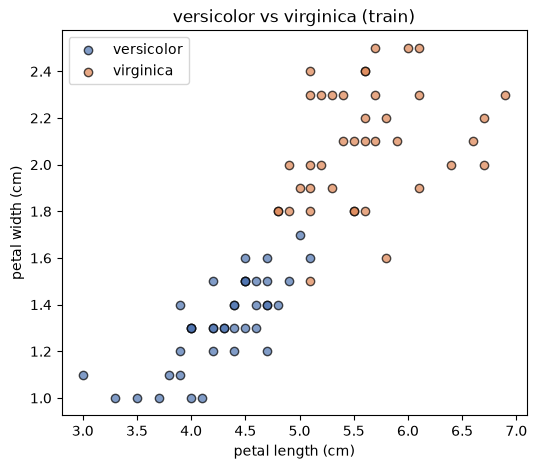

,train_acc,val_acc
Dummy most_frequent,0.5000 ± 0.0000,0.5000 ± 0.0000
Decision stump,0.9753 ± 0.0094,0.9450 ± 0.0568
Perceptron,0.9759 ± 0.0232,0.9500 ± 0.0468
Averaged perceptron,0.9728 ± 0.0192,0.9575 ± 0.0458
LogisticRegression C=1,0.9650 ± 0.0135,0.9613 ± 0.0431


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline

Xv_train, Xv_test, yv_train, yv_test = load_iris_binary(labels=(1, 2))
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

fig, ax = plt.subplots(figsize=(6, 5))
for lab, color, name in [(0, "#4C72B0", "versicolor"), (1, "#DD8452", "virginica")]:
    pts = Xv_train[yv_train == lab]
    ax.scatter(
        pts["petal length (cm)"],
        pts["petal width (cm)"],
        c=color,
        label=name,
        edgecolor="k",
        alpha=0.7,
    )
ax.set_xlabel("petal length (cm)")
ax.set_ylabel("petal width (cm)")
ax.set_title("versicolor vs virginica (train)")
ax.legend()
plt.show()


def perceptron_pipe(**kwargs) -> Pipeline:
    """StandardScaler → SGDClassifier(loss="perceptron")；預設等價於 sklearn 的 Perceptron。"""
    params = dict(
        loss="perceptron",
        learning_rate="constant",
        eta0=1.0,
        penalty=None,
        random_state=42,
    )
    params.update(kwargs)
    return make_pipeline(StandardScaler(), SGDClassifier(**params))


vv_base = pd.DataFrame(
    {
        "Dummy most_frequent": cv_summary(
            DummyClassifier(strategy="most_frequent"), Xv_train, yv_train, rcv
        ),
        "Decision stump": cv_summary(
            DecisionTreeClassifier(max_depth=1, random_state=42),
            Xv_train,
            yv_train,
            rcv,
        ),
        "Perceptron": cv_summary(perceptron_pipe(), Xv_train, yv_train, rcv),
        "Averaged perceptron": cv_summary(
            perceptron_pipe(average=True), Xv_train, yv_train, rcv
        ),
        "LogisticRegression C=1": cv_summary(
            make_pipeline(StandardScaler(), LogisticRegression()),
            Xv_train,
            yv_train,
            rcv,
        ),
    }
).T
display(vv_base)

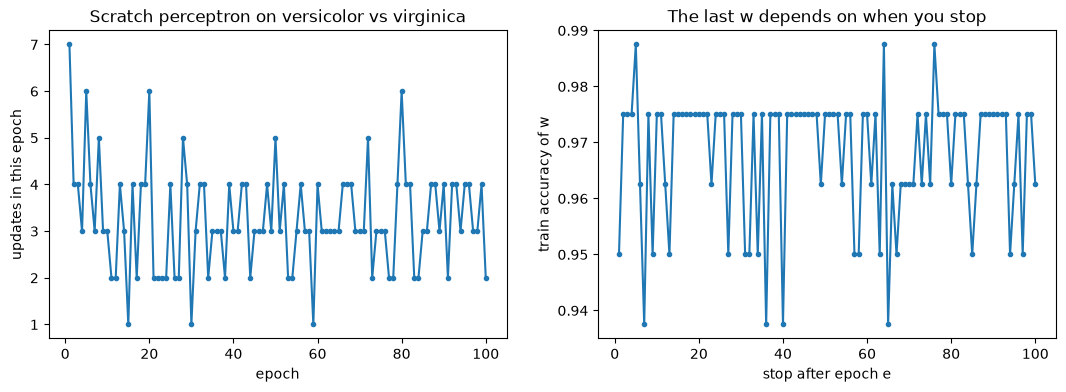

epoch 數： 100 （跑滿 max_epochs → 從來沒有一個 epoch 完全分對）
每個 epoch 更新次數的範圍： 1 – 7
各 epoch 結束時的訓練集 accuracy：min 0.9375  max 0.9875  最後 0.9625


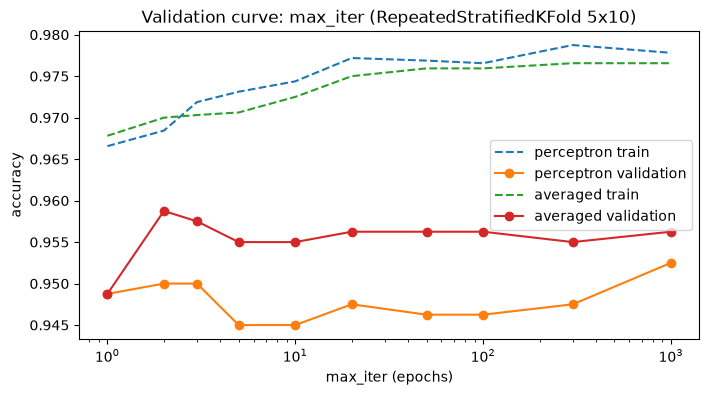

perceptron                 averaged                
              train     val val_std    train     val val_std
max_iter                                                    
1            0.9666  0.9488  0.0582   0.9678  0.9488  0.0511
2            0.9684  0.9500  0.0484   0.9700  0.9588  0.0461
3            0.9719  0.9500  0.0530   0.9703  0.9575  0.0475
5            0.9731  0.9450  0.0494   0.9706  0.9550  0.0501
10           0.9744  0.9450  0.0444   0.9725  0.9550  0.0485
20           0.9772  0.9475  0.0457   0.9750  0.9562  0.0437
50           0.9769  0.9462  0.0451   0.9759  0.9562  0.0455
100          0.9766  0.9462  0.0415   0.9759  0.9562  0.0455
300          0.9788  0.9475  0.0506   0.9766  0.9550  0.0451
1000         0.9778  0.9525  0.0443   0.9766  0.9562  0.0455

In [16]:
# 手寫感知器在線性不可分的資料上：每個 epoch 的更新次數，以及「停在第 e 個 epoch」時 w 的訓練集 accuracy
scaler_v = StandardScaler().fit(Xv_train)
Xv_train_s, Xv_test_s = scaler_v.transform(Xv_train), scaler_v.transform(Xv_test)
yv_tr_signed, yv_te_signed = yv_train.to_numpy() * 2 - 1, yv_test.to_numpy() * 2 - 1

E = 100
m_vv = Perceptron(max_epochs=E, seed=42).fit(Xv_train_s, yv_tr_signed)
# 同一個 seed 的亂數序列相同 → max_epochs = e 的模型，就是長跑模型在第 e 個 epoch 結束時的狀態
acc_by_epoch = [
    (
        Perceptron(max_epochs=e, seed=42)
        .fit(Xv_train_s, yv_tr_signed)
        .predict(Xv_train_s)
        == yv_tr_signed
    ).mean()
    for e in range(1, E + 1)
]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(range(1, E + 1), m_vv.errors_, "o-", ms=3)
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("updates in this epoch")
axes[0].set_title("Scratch perceptron on versicolor vs virginica")
axes[1].plot(range(1, E + 1), acc_by_epoch, "o-", ms=3)
axes[1].set_xlabel("stop after epoch e")
axes[1].set_ylabel("train accuracy of w")
axes[1].set_title("The last w depends on when you stop")
plt.show()
print(
    "epoch 數：", len(m_vv.errors_), "（跑滿 max_epochs → 從來沒有一個 epoch 完全分對）"
)
print("每個 epoch 更新次數的範圍：", min(m_vv.errors_), "–", max(m_vv.errors_))
print(
    "各 epoch 結束時的訓練集 accuracy：min",
    min(acc_by_epoch),
    " max",
    max(acc_by_epoch),
    " 最後",
    acc_by_epoch[-1],
)

# 單一參數掃描：max_iter（tol=None：一定跑滿，不提早停）
from sklearn.model_selection import validation_curve

its = [1, 2, 3, 5, 10, 20, 50, 100, 300, 1000]
vc = {}
for name, avg in [("perceptron", False), ("averaged", True)]:
    tr, va = validation_curve(
        perceptron_pipe(average=avg, tol=None),
        Xv_train,
        yv_train,
        param_name="sgdclassifier__max_iter",
        param_range=its,
        cv=rcv,
        scoring="accuracy",
        n_jobs=-1,
    )
    vc[name] = pd.DataFrame(
        {"train": tr.mean(1), "val": va.mean(1), "val_std": va.std(1)},
        index=pd.Index(its, name="max_iter"),
    )
fig, ax = plt.subplots(figsize=(8, 4))
for name, t in vc.items():
    ax.plot(its, t["train"], "--", label=f"{name} train")
    ax.plot(its, t["val"], "o-", label=f"{name} validation")
ax.set_xscale("log")
ax.set_xlabel("max_iter (epochs)")
ax.set_ylabel("accuracy")
ax.set_title("Validation curve: max_iter (RepeatedStratifiedKFold 5x10)")
ax.legend()
plt.show()
display(pd.concat(vc, axis=1).round(4))

### TODO 7（問答）

> **(1)** 手寫感知器在 versicolor vs virginica 上：
>
> **(a)** 讀輸出：跑了幾個 epoch？每個 epoch 的更新次數範圍？
>
> **(b)** 為什麼 `errors_` 永遠到不了 0？Novikoff 定理的哪一個前提不成立？
>
> **(c)** 右圖：「停在第 $e$ 個 epoch」的 $w$，訓練集 accuracy 在多少之間跳動？這對「最後回傳哪一個 $w$」代表什麼？

**(a)** 跑滿 100 個 epoch；每個 epoch 都有 1–7 次更新，從來沒有一個 epoch 完全沒錯。

**(b)** 資料**線性不可分**：不存在任何一條線（超平面）能把 80 筆全部分對（右圖：100 個 epoch 裡最好的 $w$ 也錯 1 筆，0.9875）。只要有一筆一定分錯，每個 epoch 至少更新一次，條件 errors = 0 永遠不成立。（反過來說：如果資料可分，Novikoff 保證有限次更新內一定收斂，不會 100 個 epoch 都停不下來。）

- Novikoff 定理的前提是「存在 margin $\gamma > 0$ 的分界線」；不可分時 $\gamma$ 不存在，上限 $(R/\gamma)^2$ 沒有意義，也就沒有收斂保證。
- 實際上 $w$ 會在幾組解之間來回打轉（perceptron cycling theorem：$w$ 會一直待在一個有界的範圍內，但不會停下來）。

**(c)** 0.9375–0.9875，最後一個 epoch 是 0.9625。同一次訓練、只是停的時間不同，訓練集 accuracy 就差了 4 筆 → 回傳「最後一個 $w$」等於從打轉的軌跡裡隨便抽一個。兩種修法：

- **Pocket algorithm**：一邊更新，一邊把「到目前為止錯最少的 $w$」放在口袋裡，最後回傳口袋裡的那一個（待補強）。
- **Averaged perceptron**：回傳所有歷史 $w$ 的平均（下一題、sklearn 的 `average=True`）。

> **(2)** Validation curve（max_iter）：
>
> **(a)** 原版感知器的 val accuracy 隨 max_iter 有明顯的趨勢嗎？跟 val_std 比，曲線的起伏大不大？
>
> **(b)** averaged 版本跟原版比，平均高多少？為什麼「平均所有歷史 $w$」會讓結果比較穩？

**(a)** 沒有趨勢：原版在 0.945–0.953 之間跳動，max_iter = 1 就已經有 0.949；起伏（< 0.01）遠小於 val_std（約 0.045）。不收斂的情況下，多跑幾個 epoch 只是讓 $w$ 繼續打轉，不會更好。

**(b)** 高約 0.005–0.01（max_iter ≥ 2 時 0.955–0.959），一樣小於一個 std，統計上分不出來。

- 直覺：$w$ 在幾組解之間來回震盪，最後一個 $w$ 是震盪中的某一個點；平均則落在震盪的「中心」，比較不受停在哪一步影響 → 變異較小。
- 也可以看成一種 ensemble：每個歷史 $w$ 都是一個分類器，平均 $w$ 近似「讓它們依存活時間加權投票」（voted perceptron，Freund & Schapire 1999）。
- averaged 的 train accuracy 反而略低（0.976 vs 0.978）、val 略高：平均把「貼合訓練集最後幾筆」的部分抹平了，是降低變異的典型現象。


In [17]:
# 搜尋：penalty × alpha × average（penalty=None 時 alpha 沒有作用，所以分成兩組 grid，避免重複）
# 註：average=True 搭配 L1 在 sklearn 會得到正負號錯亂的係數（訓練集 accuracy 只剩 0.1 左右），這裡不放進搜尋
from sklearn.model_selection import GridSearchCV

param_grid = [
    {"sgdclassifier__penalty": [None], "sgdclassifier__average": [False, True]},
    {
        "sgdclassifier__penalty": ["l2"],
        "sgdclassifier__alpha": np.logspace(-5, -1, 5),
        "sgdclassifier__average": [False, True],
    },
]
gs = GridSearchCV(perceptron_pipe(), param_grid, cv=rcv, scoring="accuracy", n_jobs=-1)
gs.fit(Xv_train, yv_train)

res = pd.DataFrame(
    {
        "penalty": [
            "none" if p is None else p
            for p in gs.cv_results_["param_sgdclassifier__penalty"]
        ],
        "alpha": [
            0.0 if a is np.ma.masked else float(a)
            for a in gs.cv_results_["param_sgdclassifier__alpha"]
        ],
        "average": gs.cv_results_["param_sgdclassifier__average"].astype(bool),
        "mean": gs.cv_results_["mean_test_score"],
        "std": gs.cv_results_["std_test_score"],
    }
)
print("best_params_：", gs.best_params_, "  CV accuracy：", round(gs.best_score_, 4))
display(
    res.pivot_table(
        index=["penalty", "alpha"], columns="average", values=["mean", "std"]
    ).round(4)
)

best_params_： {'sgdclassifier__alpha': np.float64(0.001), 'sgdclassifier__average': True, 'sgdclassifier__penalty': 'l2'}   CV accuracy： 0.96


mean             std        
average           False   True    False   True 
penalty alpha                                  
l2      0.00001  0.9500  0.9575  0.0468  0.0458
        0.00010  0.9488  0.9575  0.0479  0.0458
        0.00100  0.9450  0.9600  0.0581  0.0429
        0.01000  0.9225  0.9550  0.0619  0.0451
        0.10000  0.8812  0.9475  0.1194  0.0457
none    0.00000  0.9500  0.9575  0.0468  0.0458

In [18]:
# one-standard-error rule：跟最佳差距不到一個標準差的候選中，挑「最簡單」的
best = res.loc[res["mean"].idxmax()]

# TODO 8（程式）
#   - ok：mean ≥ best.mean − best.std 的所有列（accuracy 越高越好）
#   - choice：ok 裡最簡單的一列。這裡的「簡單」：不加正則化（alpha = 0）優先、其次 alpha 大的優先；
#     再相同時 average=False 優先（少一個技巧）
#   - 提示：先做一欄 rank = 「alpha == 0 時 0，否則 1」，再 sort_values(["rank", "alpha", "average"], ascending=[True, False, True])
ok = res[res["mean"] >= best["mean"] - best["std"]]
choice = (
    ok.assign(rank=(ok["alpha"] > 0).astype(int))
    .sort_values(["rank", "alpha", "average"], ascending=[True, False, True])
    .iloc[0]
)
print("CV 最佳 ：", best.to_dict())
print("1-SE 選擇：", choice.to_dict())
print("✅ 1-SE 應選到 penalty = none、average = False（也就是預設的感知器）")

model_1se = perceptron_pipe(
    penalty=None if choice["penalty"] == "none" else choice["penalty"],
    alpha=choice["alpha"] if choice["alpha"] > 0 else 0.0001,
    average=bool(choice["average"]),
).fit(Xv_train, yv_train)

CV 最佳 ： {'penalty': 'l2', 'alpha': 0.001, 'average': True, 'mean': 0.96, 'std': 0.04286607049870562}
1-SE 選擇： {'penalty': 'none', 'alpha': 0.0, 'average': False, 'mean': 0.95, 'std': 0.04677071733467427, 'rank': 0}
✅ 1-SE 應選到 penalty = none、average = False（也就是預設的感知器）


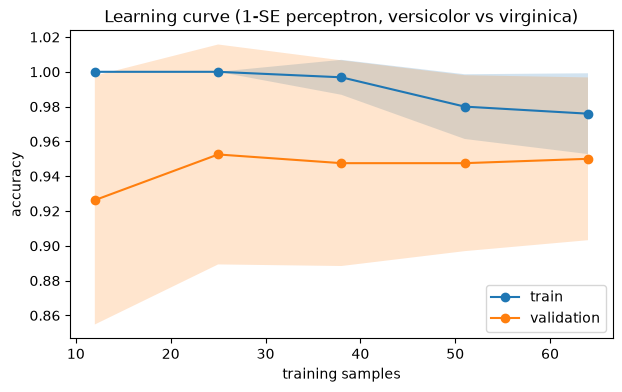

,n,train,val,val_std
0,12,1.0000,0.9262,0.0715
1,25,1.0000,0.9525,0.0632
2,38,0.9968,0.9475,0.0591
3,51,0.9800,0.9475,0.0506
4,64,0.9759,0.9500,0.0468


20 個 random_state 的 CV accuracy：min 0.9413、max 0.9575、標準差 0.0047


In [19]:
# 學習曲線，以及「換一個 random_state（資料順序）」CV 分數會差多少
from sklearn.model_selection import cross_val_score, learning_curve

sizes, tr, va = learning_curve(
    model_1se,
    Xv_train,
    yv_train,
    cv=rcv,
    scoring="accuracy",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1,
)
fig, ax = plt.subplots(figsize=(7, 4))
for name, s in [("train", tr), ("validation", va)]:
    ax.plot(sizes, s.mean(1), "o-", label=name)
    ax.fill_between(sizes, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.2)
ax.set_xlabel("training samples")
ax.set_ylabel("accuracy")
ax.set_title("Learning curve (1-SE perceptron, versicolor vs virginica)")
ax.legend()
plt.show()
display(
    pd.DataFrame(
        {"n": sizes, "train": tr.mean(1), "val": va.mean(1), "val_std": va.std(1)}
    ).round(4)
)

seed_scores = pd.Series(
    {
        s: cross_val_score(
            perceptron_pipe(random_state=s), Xv_train, yv_train, cv=rcv
        ).mean()
        for s in range(20)
    }
)
print(
    f"20 個 random_state 的 CV accuracy：min {seed_scores.min():.4f}、max {seed_scores.max():.4f}、"
    f"標準差 {seed_scores.std():.4f}"
)

### TODO 9（問答）

> **(1)** Grid search：
>
> **(a)** CV 最佳是哪一組？平均 ± 標準差？原版感知器（penalty = none、average = False）呢？
>
> **(b)** 1-SE 的門檻是多少？有哪些組合被排除？
>
> **(c)** 每個 fold 只有 16 筆。0.01 的 accuracy 差距等於幾筆樣本？一個標準差（0.045）又是幾筆？

**(a)** CV 最佳：L2、$\alpha = 0.001$、average = True，0.960 ± 0.043；原版 0.950 ± 0.047。

**(b)** 門檻 0.960 − 0.043 = 0.917。只有 L2、$\alpha = 0.1$、不平均（0.881 ± 0.119）被排除；其餘全部在一個標準差內 → 依「不加正則化 → 不平均」選到**原版感知器**。

- 被排除的那一組：sklearn 每一步做 $w \leftarrow (1 - \eta\alpha) w$，$\eta = 1$、$\alpha = 0.1$ 時每看一筆樣本 $w$ 就縮 10%，分界線還沒站穩就被拉回原點；標準差 0.119 也代表結果非常不穩。加了平均就救回來（0.948），又是「平均降低變異」。

**(c)** 0.01 × 16 = 0.16 筆；一個標準差 0.045 × 16 ≈ 0.7 筆。最佳與原版差 0.01，等於「每 6 個 fold 多對 1 筆」—— 在 80 筆的資料上，這些設定實際上沒有差別。

> **(2)** 學習曲線：
>
> **(a)** n = 12、25 時 train accuracy 是 1.0，n = 64 時變成 0.976。為什麼資料少的時候反而能全部分對？
>
> **(b)** val 從 0.926 升到 0.95 之後就平了。再加資料會更好嗎？瓶頸在哪？

**(a)** 兩類只在少數幾筆樣本上重疊（全部 80 筆裡最好的線也要錯 1 筆，TODO 7 (1)）。只抽 12、25 筆時，這幾筆「越界」的樣本很可能沒被抽到，子集就是線性可分的，感知器能收斂到全對；樣本越多，越可能同時抽到重疊區的樣本，train accuracy 就掉到 0.98 左右。

- 所以小樣本的 train = 1.0 不代表模型強，而是「資料還沒多到暴露出重疊」。

**(b)** 不太會。val 0.95 已經離「訓練集上最好的線」（0.9875）不遠，train 與 val 的差距（0.026）也不大。瓶頸是**資料本身的重疊**：用這 4 個特徵，有些 versicolor 與 virginica 長得幾乎一樣，任何線性分界都會錯幾筆 —— 加資料、調超參數都改變不了。

> **(3)** 20 個 `random_state`（資料順序）的 CV accuracy 在 0.941–0.958 之間，標準差 0.0047。跟 fold 之間的標準差（約 0.047）比，seed 的影響大還是小？

小一個數量級：這裡每個 seed 的分數已經是 50 個 fold 的平均，fold 間的雜訊被平均掉了，剩下 seed 本身的影響約 ±0.005。

- 但單一模型、單一的 20 筆測試集時，seed 的影響會被放大：換 seed 就是換一條分界線，重疊區的 1–2 筆樣本可能因此換邊，而 1 筆就是 0.05（第 6 節的幾個模型正好都差 1 筆）。
- → 報告感知器的成績時，最好附上「多個 seed 的平均與標準差」，或改用比較穩定的 averaged 版本。


---
## 6. 測試集評估

兩個 benchmark 各評估一次：主資料記在 `iris_binary`，versicolor vs virginica 記在 `iris_versicolor_virginica`。


,accuracy,precision,recall,f1,roc_auc
Dummy most_frequent,0.5,0.0,0.0,0.0,0.5
Perceptron (scratch),1.0,1.0,1.0,1.0,1.0
Perceptron (sklearn),1.0,1.0,1.0,1.0,1.0


,accuracy,precision,recall,f1,roc_auc
Dummy most_frequent,0.50,0.0000,0.0,0.0000,0.50
"Perceptron (scratch, 100 epochs)",0.95,1.0000,0.9,0.9474,0.99
Perceptron 1-SE (sklearn),0.90,0.8333,1.0,0.9091,1.00
Perceptron CV-best (sklearn),0.95,1.0000,0.9,0.9474,0.98
"LogisticRegression C=1 (sklearn, ref)",0.90,0.9000,0.9,0.9000,0.99


,model,accuracy,time,precision,recall,f1,roc_auc,params,notes
0,"Perceptron (scratch, 100 epochs)",0.95,2026-10-24 22:28,1.0000,0.9,0.9474,0.99,"{""epochs"": 100, ""seed"": 42}",NaN
1,Perceptron CV-best (sklearn),0.95,2026-10-24 22:28,1.0000,0.9,0.9474,0.98,"{""alpha"": 0.001, ""average"": true, ""penalty"": ""...",NaN
2,Perceptron 1-SE (sklearn),0.90,2026-10-24 22:28,0.8333,1.0,0.9091,1.00,"{""penalty"": ""none"", ""average"": false}",NaN
3,"LogisticRegression C=1 (sklearn, ref)",0.90,2026-10-24 22:28,0.9000,0.9,0.9000,0.99,"{""C"": 1.0}",NaN
4,Dummy most_frequent,0.50,2026-10-24 22:28,0.0000,0.0,0.0000,0.50,NaN,NaN


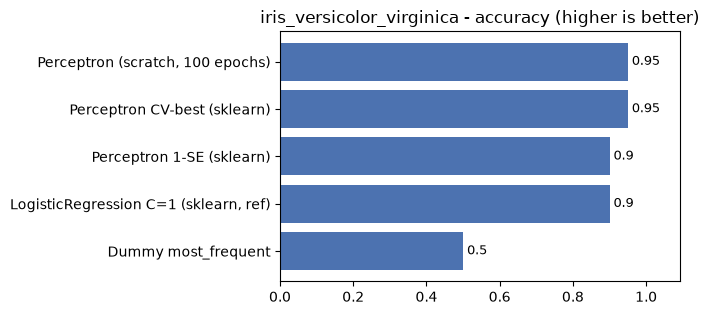

In [20]:
from ml_dl_llm.metrics import classification_metrics
from ml_dl_llm.results import compare, log_result

# ---- 主資料（setosa vs versicolor，標籤 −1／+1）
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
main_models = {
    "Dummy most_frequent": (
        dummy.predict(X_test),
        dummy.predict_proba(X_test)[:, 1],
        {},
    ),
    "Perceptron (scratch)": (
        model.predict(X_test_s),
        model.decision_function(X_test_s),  # 分數也可以拿來算 ROC AUC
        {
            "lr": model.lr,
            "seed": model.seed,
            "scaled": True,
            "updates": sum(model.errors_),
        },
    ),
    "Perceptron (sklearn)": (
        sk_model.predict(X_test),
        sk_model.decision_function(X_test),
        {"random_state": 42},
    ),
}
scores = {}
for name, (pred, score, params) in main_models.items():
    m = classification_metrics(y_test, pred, score, average="binary")  # 正類是 +1
    scores[name] = m
    log_result("iris_binary", name, m, **params)
display(pd.DataFrame(scores).T)

# ---- versicolor vs virginica（標籤 0／1）
dummy_v = DummyClassifier(strategy="most_frequent").fit(Xv_train, yv_train)
logreg_v = make_pipeline(StandardScaler(), LogisticRegression()).fit(Xv_train, yv_train)
vv_models = {
    "Dummy most_frequent": (
        dummy_v.predict(Xv_test),
        dummy_v.predict_proba(Xv_test)[:, 1],
        {},
    ),
    "Perceptron (scratch, 100 epochs)": (
        (m_vv.predict(Xv_test_s) + 1) // 2,
        m_vv.decision_function(Xv_test_s),
        {"epochs": E, "seed": 42},
    ),
    "Perceptron 1-SE (sklearn)": (
        model_1se.predict(Xv_test),
        model_1se.decision_function(Xv_test),
        {"penalty": choice["penalty"], "average": bool(choice["average"])},
    ),
    "Perceptron CV-best (sklearn)": (
        gs.best_estimator_.predict(Xv_test),
        gs.best_estimator_.decision_function(Xv_test),
        {k.split("__")[1]: v for k, v in gs.best_params_.items()},
    ),
    "LogisticRegression C=1 (sklearn, ref)": (
        logreg_v.predict(Xv_test),
        logreg_v.predict_proba(Xv_test)[:, 1],
        {"C": 1.0},
    ),
}
scores_v = {}
for name, (pred, score, params) in vv_models.items():
    m = classification_metrics(yv_test, pred, score)
    scores_v[name] = m
    log_result("iris_versicolor_virginica", name, m, **params)
display(pd.DataFrame(scores_v).T)
compare("iris_versicolor_virginica", "accuracy")

---
## 7. 診斷

主資料 accuracy = 1.0，能看的是「分界線落在哪裡」；versicolor vs virginica 則看錯在哪些樣本。


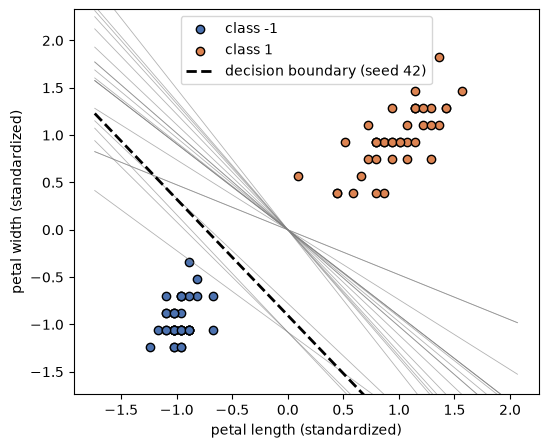

更新次數： [1, 0]


In [21]:
# 主資料：四個特徵應該畫四維圖，但是畫不出來所以用二維去觀察就好
# 除了 seed 42，再疊上 20 個 seed 的分界線：每個 seed 都能分開，但線不一樣（TODO 5、TODO 10 (1)）
import numpy as np
import matplotlib.pyplot as plt

cols = [2, 3]  # petal length、petal width
X2 = X_train_s[:, cols]
m2 = Perceptron(seed=42).fit(X2, y_train)

# 分界線：w1*x1 + w2*x2 + b = 0  →  x2 = -(w1*x1 + b) / w2
w1, w2 = m2.w_
xs = np.linspace(X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5, 100)
ys = -(w1 * xs + m2.b_) / w2

fig, ax = plt.subplots(figsize=(6, 5))
for label, color in [(-1, "#4C72B0"), (1, "#DD8452")]:
    pts = X2[y_train == label]
    ax.scatter(pts[:, 0], pts[:, 1], c=color, label=f"class {label}", edgecolor="k")
for s in range(20):
    ms = Perceptron(seed=s).fit(X2, y_train)
    ax.plot(xs, -(ms.w_[0] * xs + ms.b_) / ms.w_[1], color="gray", lw=0.6, alpha=0.6)
ax.plot(xs, ys, "k--", lw=2, label="decision boundary (seed 42)")
ax.set_xlabel("petal length (standardized)")
ax.set_ylabel("petal width (standardized)")
ax.set_ylim(X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5)
ax.legend()
plt.show()
print("更新次數：", m2.errors_)

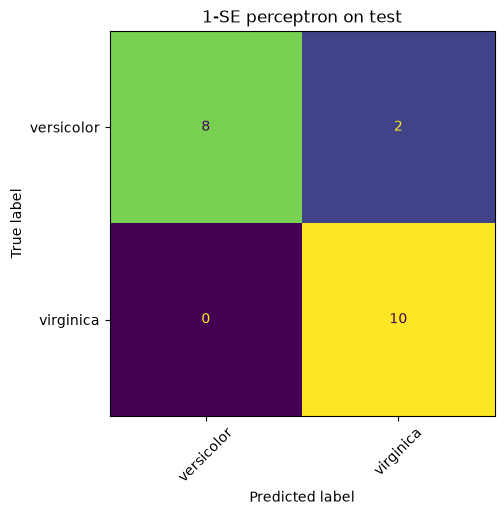

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),true,pred,score
18,6.2,2.2,4.5,1.5,0,1,0.24
22,6.3,2.5,4.9,1.5,0,1,0.25


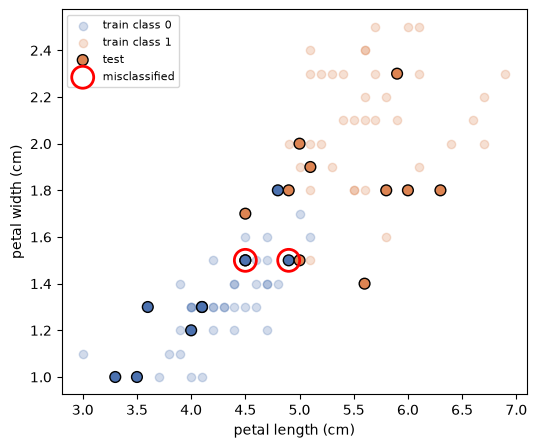

感知器途中最好的 w，訓練集 accuracy： 0.9875 （錯 1 筆）
近乎不正則化的邏輯回歸，訓練集 accuracy： 0.975


In [ ]:
# versicolor vs virginica：混淆矩陣與測試集的錯誤樣本
from ml_dl_llm.metrics import plot_confusion_matrix

pred_v = model_1se.predict(Xv_test)
plot_confusion_matrix(yv_test, pred_v, labels=["versicolor", "virginica"])
plt.title("1-SE perceptron on test")
plt.show()

wrong = pred_v != yv_test.to_numpy()
display(
    Xv_test[wrong].assign(
        true=yv_test[wrong],
        pred=pred_v[wrong],
        score=model_1se.decision_function(Xv_test)[wrong].round(2),
    )
)

# 錯誤樣本在 petal 平面上的位置（灰色 = 訓練集）
fig, ax = plt.subplots(figsize=(6, 5))
for lab, color in [(0, "#4C72B0"), (1, "#DD8452")]:
    pts = Xv_train[yv_train == lab]
    ax.scatter(
        pts["petal length (cm)"],
        pts["petal width (cm)"],
        c=color,
        alpha=0.25,
        label=f"train class {lab}",
    )
ax.scatter(
    Xv_test["petal length (cm)"],
    Xv_test["petal width (cm)"],
    c=np.where(yv_test == 0, "#4C72B0", "#DD8452"),
    edgecolor="k",
    s=60,
    label="test",
)
ax.scatter(
    Xv_test.loc[wrong, "petal length (cm)"],
    Xv_test.loc[wrong, "petal width (cm)"],
    facecolor="none",
    edgecolor="r",
    s=250,
    lw=2,
    label="misclassified",
)
ax.set_xlabel("petal length (cm)")
ax.set_ylabel("petal width (cm)")
ax.legend(fontsize=8)
plt.show()

# 線性模型在「訓練集」上能分對多少？
#   - 手寫感知器 100 個 epoch 裡最好的那個 w（5B 右圖的最高點）
#   - 近乎不正則化的邏輯回歸（它最小化 log loss，不是最小化「錯幾筆」）
best_linear = make_pipeline(
    StandardScaler(), LogisticRegression(C=1e4, max_iter=10_000)
).fit(Xv_train, yv_train)
print(
    "感知器途中最好的 w，訓練集 accuracy：",
    max(acc_by_epoch),
    f"（錯 {round((1 - max(acc_by_epoch)) * 80)} 筆）",
)
print(
    "近乎不正則化的邏輯回歸，訓練集 accuracy：",
    (best_linear.predict(Xv_train) == yv_train).mean(),
)

### TODO 10（問答）本章總結

> **(1)** 主資料的分界線圖（只用 petal 兩個特徵、標準化後）：
>
> **(a)** 20 個 seed 的灰線都能把訓練集分開嗎？它們長得一樣嗎？
>
> **(b)** 很多條灰線都通過原點。這些 seed 各更新了幾次？為什麼 $b$ 會剛好是 0？
>
> **(c)** 跟 TODO 5 (2) 的 margin 有什麼關係？

**(a)** 都能分開（線性可分，每個 seed 都收斂），但斜率與位置都不一樣：有的貼近 setosa（例如 seed 42 的黑色虛線），有的幾乎擦過 versicolor 最左邊那一點。

**(b)** 20 個 seed 裡有 15 個更新了 2 次：一次是分錯的 +1 樣本（$b$ 加 1）、一次是分錯的 −1 樣本（$b$ 減 1）→ $b = 0$，線通過原點；$w = x_+ - x_-$，分界線就是「垂直於這兩點連線、通過原點」的直線。標準化後原點就是資料中心，剛好落在兩群之間，所以這樣也分得開。另外 5 個（含 seed 42）只更新 1 次，$b = 1$，線被平移離開原點。

- 也就是說：分界線長什麼樣子，完全由「最先被分錯的那一兩筆樣本是誰」決定。

**(c)** 這就是 TODO 5 (2) margin 從 0.011 到 0.84 的樣子 —— 感知器的答案是「所有能分開的線」裡的任意一條，由資料順序決定；擦過某個樣本的那幾條就是 margin 很小的解。

> **(2)** versicolor vs virginica 的測試集：
>
> **(a)** 讀表：scratch、1-SE、CV 最佳、邏輯回歸的 accuracy 各是多少？測試集 20 筆，差距等於幾筆？
>
> **(b)** 1-SE 模型（0.90）在測試集上比 CV 最佳（0.95）差。要不要改用 CV 最佳？
>
> **(c)** 1-SE 模型的 accuracy 只有 0.90，ROC AUC 卻是 1.00。看錯誤樣本的 score 欄：兩者為什麼不矛盾？

**(a)** scratch 0.95、CV 最佳 0.95、1-SE 0.90、邏輯回歸 0.90。差距全部是 **1 筆**（1 筆 = 0.05）。

**(b)** 不要。測試集只能看一次；「看到測試集分數之後再換模型」等於用測試集選模型，它就不再是公正的測試集（README 資料切分原則）。而且 CV 已經說了這些模型差不到一個標準差，測試集上差 1 筆也在 seed 造成的波動範圍內（TODO 9 (3)），不是真的差異。

**(c)** 兩筆錯誤的 score 是 0.24、0.25，都只比 0 大一點點：

- ROC AUC 只看排序：所有 virginica 的分數都比所有 versicolor 高 → 存在一個門檻能全部分對，AUC = 1.0。
- accuracy 用固定門檻 0：這兩筆 versicolor 剛好落在 0 和「完美門檻」之間 → 被判成 virginica。
- 也就是說，**分界線的方向（$w$）是對的，位置（$b$）偏了一點**。感知器的 $b$ 只是「最後一次更新停在哪裡」，沒有對任何準則最佳化；邏輯回歸的 $b$ 則是最大概似估計的一部分。

> **(3)** 錯誤樣本在 petal 平面上的位置：它們落在哪裡？訓練集上連最好的線都分不完 —— 這次的瓶頸在資料、特徵、還是模型？

兩筆都是 versicolor（petal length 4.5、4.9，petal width 1.5），落在兩類交界的重疊區：周圍的訓練樣本 versicolor 和 virginica 都有。

- 訓練集上沒有任何一條線能全部分對：感知器途中最好的 $w$ 錯 1 筆（0.9875），近乎不正則化的邏輯回歸錯 2 筆（0.975；它最小化 log loss，不是錯誤數）。stump（0.945）、averaged perceptron（0.958）、邏輯回歸（0.961）的 CV 分數也都擠在一起。
- 瓶頸主要在**資料**（兩個物種在這些量測上本來就有重疊），其次是特徵（只有 4 個量測）；不是模型或超參數。

> **(4)** 跟第三章的邏輯回歸比：感知器與邏輯回歸都是線性分類器，差在哪裡？

| | 感知器 | 邏輯回歸 |
| --- | --- | --- |
| loss | $\max(0, -y z)$（$z = w \cdot x + b$）：分對就是 0，不管分得多有把握 | log loss $\log(1 + e^{-y z})$：分對了也還有一點 loss，越有把握越小 |
| 更新 | 只在分錯（或落在線上）時更新，一次加上整個 $\pm x$ | 每一筆都貢獻梯度，權重 $\sigma(z) - y$：越錯推得越用力 |
| 學習率 | 從 0 開始時完全不影響結果（TODO 6） | 決定收斂與否 |
| 輸出 | 分數 $z$，只有正負號有意義 | 機率 $\sigma(z)$，可以校準 |
| 線性可分時 | 收斂到「某一條」能分開的線，不唯一 | 不加正則化時 $\|w\| \to \infty$（第三章 TODO 8）；加正則化後解唯一 |
| 線性不可分時 | 不收斂，$w$ 一直打轉 → 要 pocket／平均 | 照常收斂到唯一的最佳解 |

一句話：感知器只問「分對了沒」，邏輯回歸還問「有多確定」。這個差別讓邏輯回歸的解唯一、能給機率、在不可分的資料上也能收斂；感知器則是最簡單的「錯誤驅動」學習規則，也是第二章 MLP 的起點。


---
## 8. 本章小結

### 結果

主資料：Iris setosa vs versicolor（train 80 / test 20，線性可分；CV = 5-fold 分層）。

| 模型 | 資料 | CV accuracy | test accuracy／F1／ROC AUC | 收斂 |
| --- | --- | --- | --- | --- |
| Dummy most_frequent | — | 0.500 ± 0.000 | 0.50 | — |
| Decision stump（petal length ≤ 2.45） | raw | 1.000 ± 0.000 | — | — |
| Perceptron（手寫） | 標準化 | — | 1.0 | seed 42：1 次更新、2 個 epoch |
| Perceptron（sklearn） | 標準化（Pipeline） | 1.000 ± 0.000 | 1.0 | `n_iter_` = 6 |

200 個 seed 的平均總更新次數：raw ≈ 8.41、標準化 ≈ 1.76；幾何 margin 0.011–0.84。

調參練習：Iris versicolor vs virginica（train 80 / test 20，線性不可分；CV = 5-fold × 10 次重複）。

| 模型 | CV accuracy | test accuracy | 說明 |
| --- | --- | --- | --- |
| Dummy most_frequent | 0.500 ± 0.000 | 0.50 | — |
| Decision stump | 0.945 ± 0.057 | — | 只用一個特徵 |
| Perceptron（手寫，100 epochs） | — | 0.95 | 永遠不收斂，停在第 100 個 epoch 的 $w$ |
| Perceptron 1-SE（= 預設，sklearn） | 0.950 ± 0.047 | 0.90 | ROC AUC 1.00：方向對、$b$ 偏了 |
| Perceptron CV 最佳（L2 α=0.001、average） | 0.960 ± 0.043 | 0.95 | 與 1-SE 差不到一個 std |
| LogisticRegression C=1（對照） | 0.961 ± 0.043 | 0.90 | — |

測試集 1 筆 = 0.05，所有模型的差距都是 1 筆；訓練集上沒有任何一條線能全部分對（感知器途中最好的 $w$ 錯 1 筆）。

### 核心觀念

1. **模型**：$\hat y = \operatorname{sign}(w \cdot x + b)$，分界為超平面 $w \cdot x + b = 0$；$w$ 是超平面的法向量。
2. **錯誤驅動更新**：只在 $y (w \cdot x + b) \le 0$（分錯或落在線上）時更新 $w \leftarrow w + \eta y x$、$b \leftarrow b + \eta y$；分對就不動。條件必須含「= 0」，否則初始 $w = 0$、$b = 0$ 時永遠不會更新。
3. **收斂定理（Novikoff, 1962）**：資料線性可分、margin 為 $\gamma$、所有樣本 $\|x\| \le R$ 時，更新次數 $\le (R/\gamma)^2$，與樣本數和維度無關。單一特徵就分得開 ⇒ 線性可分。
4. **標準化的作用**：讓資料以原點為中心並縮小 $R$；未標準化時資料離原點遠，分界線主要靠每次只動 $\pm\eta$ 的 bias 慢慢平移，需要更多更新（epoch 數差不多，差在每個 epoch 的更新次數）。
5. **學習率不重要**：$w$、$b$ 從 0 開始時，換 lr 只是把整條更新序列乘上一個正數，正負號、更新順序、預測完全相同；加了正則化或初始值不為 0 時才有影響。
6. **解不唯一**：只要能分開就停，不同 seed（資料順序）會得到不同的 $w$，幾何 margin 可以差 70 倍；感知器不追求「最好」的分界線（最大 margin → SVM）。
7. **線性不可分時不收斂**：每個 epoch 都有分錯 → $w$ 一直打轉，最後回傳的 $w$ 取決於停在哪一步（訓練集 accuracy 0.94–0.99 跳動）。解法：Pocket（保留錯最少的 $w$）、Averaged perceptron（平均所有歷史 $w$，降低變異）。
8. **sklearn 的 `Perceptron`**：等價於 `SGDClassifier(loss="perceptron", learning_rate="constant", eta0=1, penalty=None)`；`shuffle=False` 時與手寫版逐步完全相同。預設 `tol=1e-3`、`n_iter_no_change=5`，loss 連續 5 個 epoch 沒改善才停，所以 `n_iter_` 是 6，而不是手寫版的 2；$w$ 不同只是因為資料順序不同。
9. **小資料的評估**：80 筆、每 fold 16 筆時 accuracy 的刻度是 0.0625，各設定的差距（0.01 ≈ 0.16 筆）遠小於標準差（≈ 0.7 筆）→ 用重複 CV 讓平均穩定、用 1-SE rule 選最簡單的模型；測試集 20 筆時差 1 筆不代表真的比較好，也不能看了測試集再換模型。
10. **accuracy vs ROC AUC**：AUC 只看排序（$w$ 的方向），accuracy 還看門檻（$b$ 的位置）；感知器的 $b$ 沒有對任何準則最佳化，常出現「AUC 1.0、accuracy 0.9」。
11. **瓶頸在資料時**：訓練集上沒有任何一條線能全部分對（兩個物種在 4 個量測上本來就重疊），所有線性模型的 CV 都擠在 0.95–0.96 → 調參、換線性模型都沒用。

### 待補強（之後回來可以學）

**理論**
- [ ] 手推 Novikoff 收斂定理的證明（兩個不等式：$w \cdot w^*$ 線性成長、$\|w\|^2$ 至多線性成長）
- [ ] 實際算出本資料的 $R$ 與 $\gamma$（用 SVM 求最大 margin 的 $w^*$），驗證 $(R/\gamma)^2$ 上限與實際更新次數的差距
- [x] 學習率不重要：w、b 從 0 開始時，η 只會等比例縮放 w 和 b（第 5 節 5A 驗證，TODO 6 證明）
- [ ] 感知器 = 對 loss $\max(0, -y(w \cdot x + b))$ 做 SGD；與 hinge loss（SVM）、log loss（邏輯回歸）比較三者的 loss 曲線
- [x] 幾何 margin：$|w \cdot x + b| / \|w\|$（TODO 5 (2)）；`decision_function` 是未正規化的分數，不是機率（要機率 → 邏輯回歸）
- [ ] Perceptron cycling theorem：不可分時 $w$ 為什麼有界

**線性不可分的情況**
- [x] 換成 versicolor vs virginica（`load_iris_binary(labels=(1, 2))`）：觀察 errors_ 不會歸零、w 來回震盪（第 5 節 5B、TODO 7）
- [ ] Pocket algorithm：保留目前錯誤最少的 w（手寫，跟 averaged 比較）
- [x] Averaged perceptron：平均所有歷史 w（sklearn `average=True`，TODO 7 (2)）；[ ] Voted perceptron 手寫
- [ ] XOR 問題與 Minsky & Papert（1969）：單層感知器的極限 → 多層感知器（MLP）與反向傳播的動機

**延伸**
- [x] 不同 seed 畫出多條分界線疊在一起（第 7 節）；[ ] 對照 SVM 的最大 margin 分界線
- [ ] 多類別感知器：one-vs-rest，或對每類各一組 w、取分數最大者（用 Iris 三類）
- [ ] Kernel perceptron（對偶形式：$w = \sum \alpha_i y_i x_i$，只用內積）→ 銜接 SVM 的 kernel trick
- [ ] Online learning：資料逐筆到來時的更新與 mistake bound
- [ ] 感知器的 $b$ 沒有最佳化：用 CV 另外調門檻，或改用 SVM／邏輯回歸

**評估方式**
- [x] 測試集只有 20 筆、且 setosa vs versicolor 太容易分：改用交叉驗證，並換成較難的類別組合比較（第 5 節）
- [x] 手寫版與 sklearn 版係數不同的原因：資料順序、停止條件（TODO 5 (1)：`shuffle=False` 時完全一致）
- [ ] 小測試集上比較兩個模型：McNemar 檢定、bootstrap 信賴區間；多個 seed 的平均與標準差
